Slicing source bathymetry to domain: (186.0, 206.0) x (62.0, 69.0) with buffer 0.5
  Resolution Diagnostics

  Source dataset (GEBCO_2024_coarse_x8.nc):
    dlon = 120.0 arcsec  (0.033333°)
    dlat = 120.0 arcsec  (0.033333°)
    dx   ~ 1768 m)
    dy   ~ 3706 m

  Model grid (T-cell spacing):
    median = 5.97 km
    min    = 5.55 km
    max    = 6.35 km

  Resolution ratio (model dx / dataset dx):
    median = 3.4x
    max    = 3.6x

  Cressman / stats-mask threshold: 12x
  → RECOMMENDED: direct_xesmf_regrid()  (bilinear / conservative)
    Ratio 3.4x is below the threshold where Cressman
    likely provides benefit over xesmf regridding.
Resolution diagnostics recommend not using stats-based masking, so we'll use the natural earth mask
The manual mask is not initialized. Initializing it now from the depth raw mask
Resolution diagnostics recommend not using stats-based depth method, so we'll do a direct xesmf regrid for depth because no depth option was specified
**NOTE**
          

/glade/work/manishrv/conda-envs/CrocoDash/lib/python3.11/site-packages/xesmf/backend.py:42: UserWarning: Input array is not F_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not F_CONTIGUOUS. ' 'Will affect performance.')


Warning! This was an opionated workflow function that ran multiple steps in sequence. Please edit the mask manually if need be (Some depth methods, like cressman, are mask-aware and may need to be rerun)! 


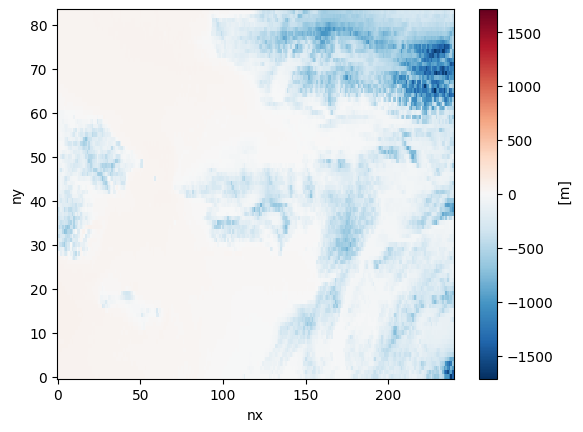

In [1]:
from CrocoDash.grid import Grid
from CrocoDash.topo import Topo
grid = Grid(
  resolution = 1/12, # in degrees
  xstart = 186, # min longitude in [0, 360]
  lenx = 20.0, # longitude extent in degrees
  ystart = 62.0, # min latitude in [-90, 90]
  leny = 7.0, # latitude extent in degrees
  name = "small_alaska",
)
topo = Topo(grid, min_depth = 1.0)

topo.set_from_dataset(
    bathymetry_path = "/glade/campaign/cesm/cesmdata/inputdata/ocn/mom/croc/crocogallerydata/gebco/GEBCO_2024_coarse_x8.nc",
    longitude_coordinate_name="lon",
    latitude_coordinate_name="lat",
    vertical_coordinate_name="elevation",
)
topo.depth.plot()

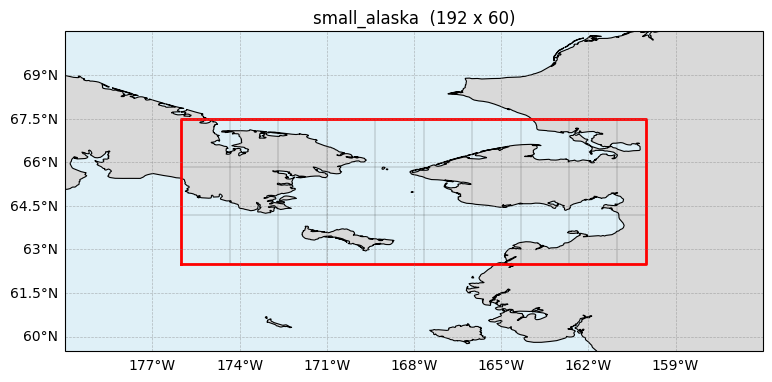

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from CrocoDash.grid import Grid
grid = Grid(
  resolution = 1/12, # in degrees
  xstart = 184, # min longitude in [0, 360]
  lenx = 16.0, # longitude extent in degrees
  ystart = 62.5, # min latitude in [-90, 90]
  leny = 5.0, # latitude extent in degrees
  name = "small_alaska",
)
# center the map on the domain; wrap corner lons so [0,360] / dateline domains stay contiguous
lon0 = float(grid.tlon.values.mean())
crs = ccrs.PlateCarree(central_longitude=lon0)
x = ((np.asarray(grid.qlon) - lon0 + 180) % 360) - 180
y = np.asarray(grid.qlat)

ax = plt.figure(figsize=(9, 6)).add_subplot(1, 1, 1, projection=crs)
ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="0.85")
ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#dff0f7")
ax.coastlines(resolution="10m", lw=0.8)

# every 20th grid line
for j in range(0, x.shape[0], 20):
    ax.plot(x[j, :], y[j, :], transform=crs, color="k", lw=0.3, alpha=0.5)
for i in range(0, x.shape[1], 20):
    ax.plot(x[:, i], y[:, i], transform=crs, color="k", lw=0.3, alpha=0.5)

# domain outline
ax.plot(np.concatenate([x[0, :], x[:, -1], x[-1, ::-1], x[::-1, 0]]),
        np.concatenate([y[0, :], y[:, -1], y[-1, ::-1], y[::-1, 0]]),
        transform=crs, color="red", lw=2)

gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, lw=0.5,
                  color="gray", alpha=0.5, linestyle="--")
gl.top_labels = gl.right_labels = False
ax.set_extent([x.min() - 4, x.max() + 4, y.min() - 3, y.max() + 3], crs=crs)
ax.set_title(f"{grid.name}  ({grid.nx} x {grid.ny})")
plt.show()
